In [2]:
%pip install --quiet numpy matplotlib scipy pywavelets neurokit2 wfdb

Note: you may need to restart the kernel to use updated packages.


ECG-ID database already exists, skipping download.

--- Processing Subject 01 ---
  Detected 24 R-peaks, extracted 24 beats for subject 01 (fs=500)

--- Processing Subject 02 ---
  Detected 23 R-peaks, extracted 23 beats for subject 02 (fs=500)

--- Processing Subject 03 ---
  Detected 25 R-peaks, extracted 25 beats for subject 03 (fs=500)

--- Processing Subject 04 ---
  Detected 23 R-peaks, extracted 23 beats for subject 04 (fs=500)

--- Processing Subject 05 ---
  Detected 18 R-peaks, extracted 18 beats for subject 05 (fs=500)

--- Processing Subject 06 ---
  Detected 26 R-peaks, extracted 26 beats for subject 06 (fs=500)

--- Processing Subject 07 ---
  Detected 27 R-peaks, extracted 27 beats for subject 07 (fs=500)

--- Processing Subject 08 ---
  Detected 29 R-peaks, extracted 29 beats for subject 08 (fs=500)

--- Processing Subject 09 ---
  Detected 20 R-peaks, extracted 20 beats for subject 09 (fs=500)

--- Processing Subject 10 ---
  Detected 28 R-peaks, extracted 28 beats for

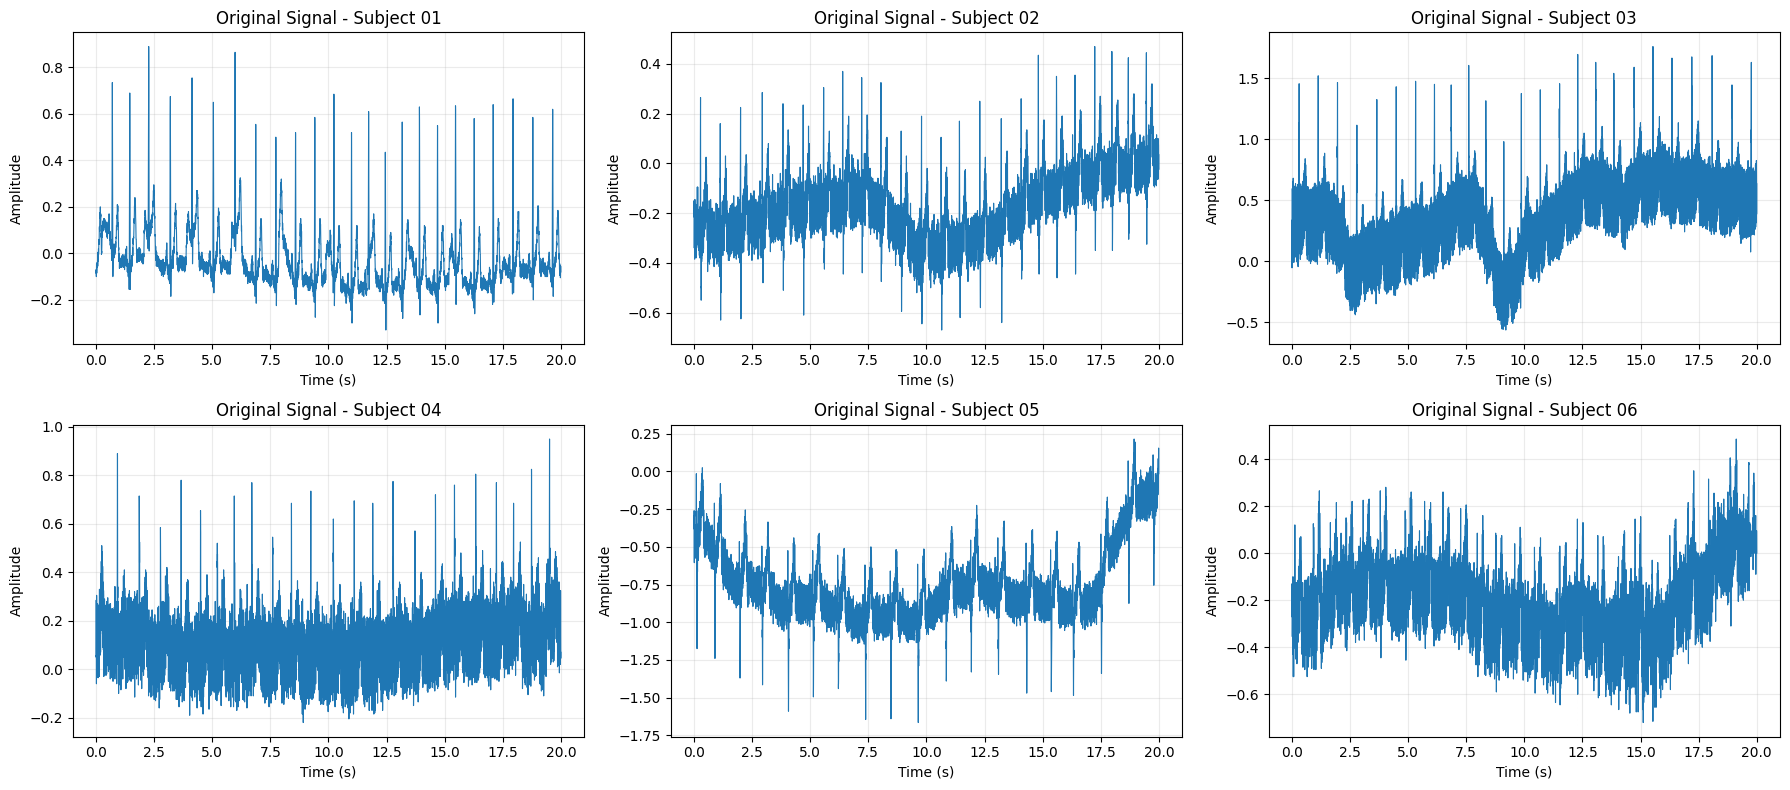

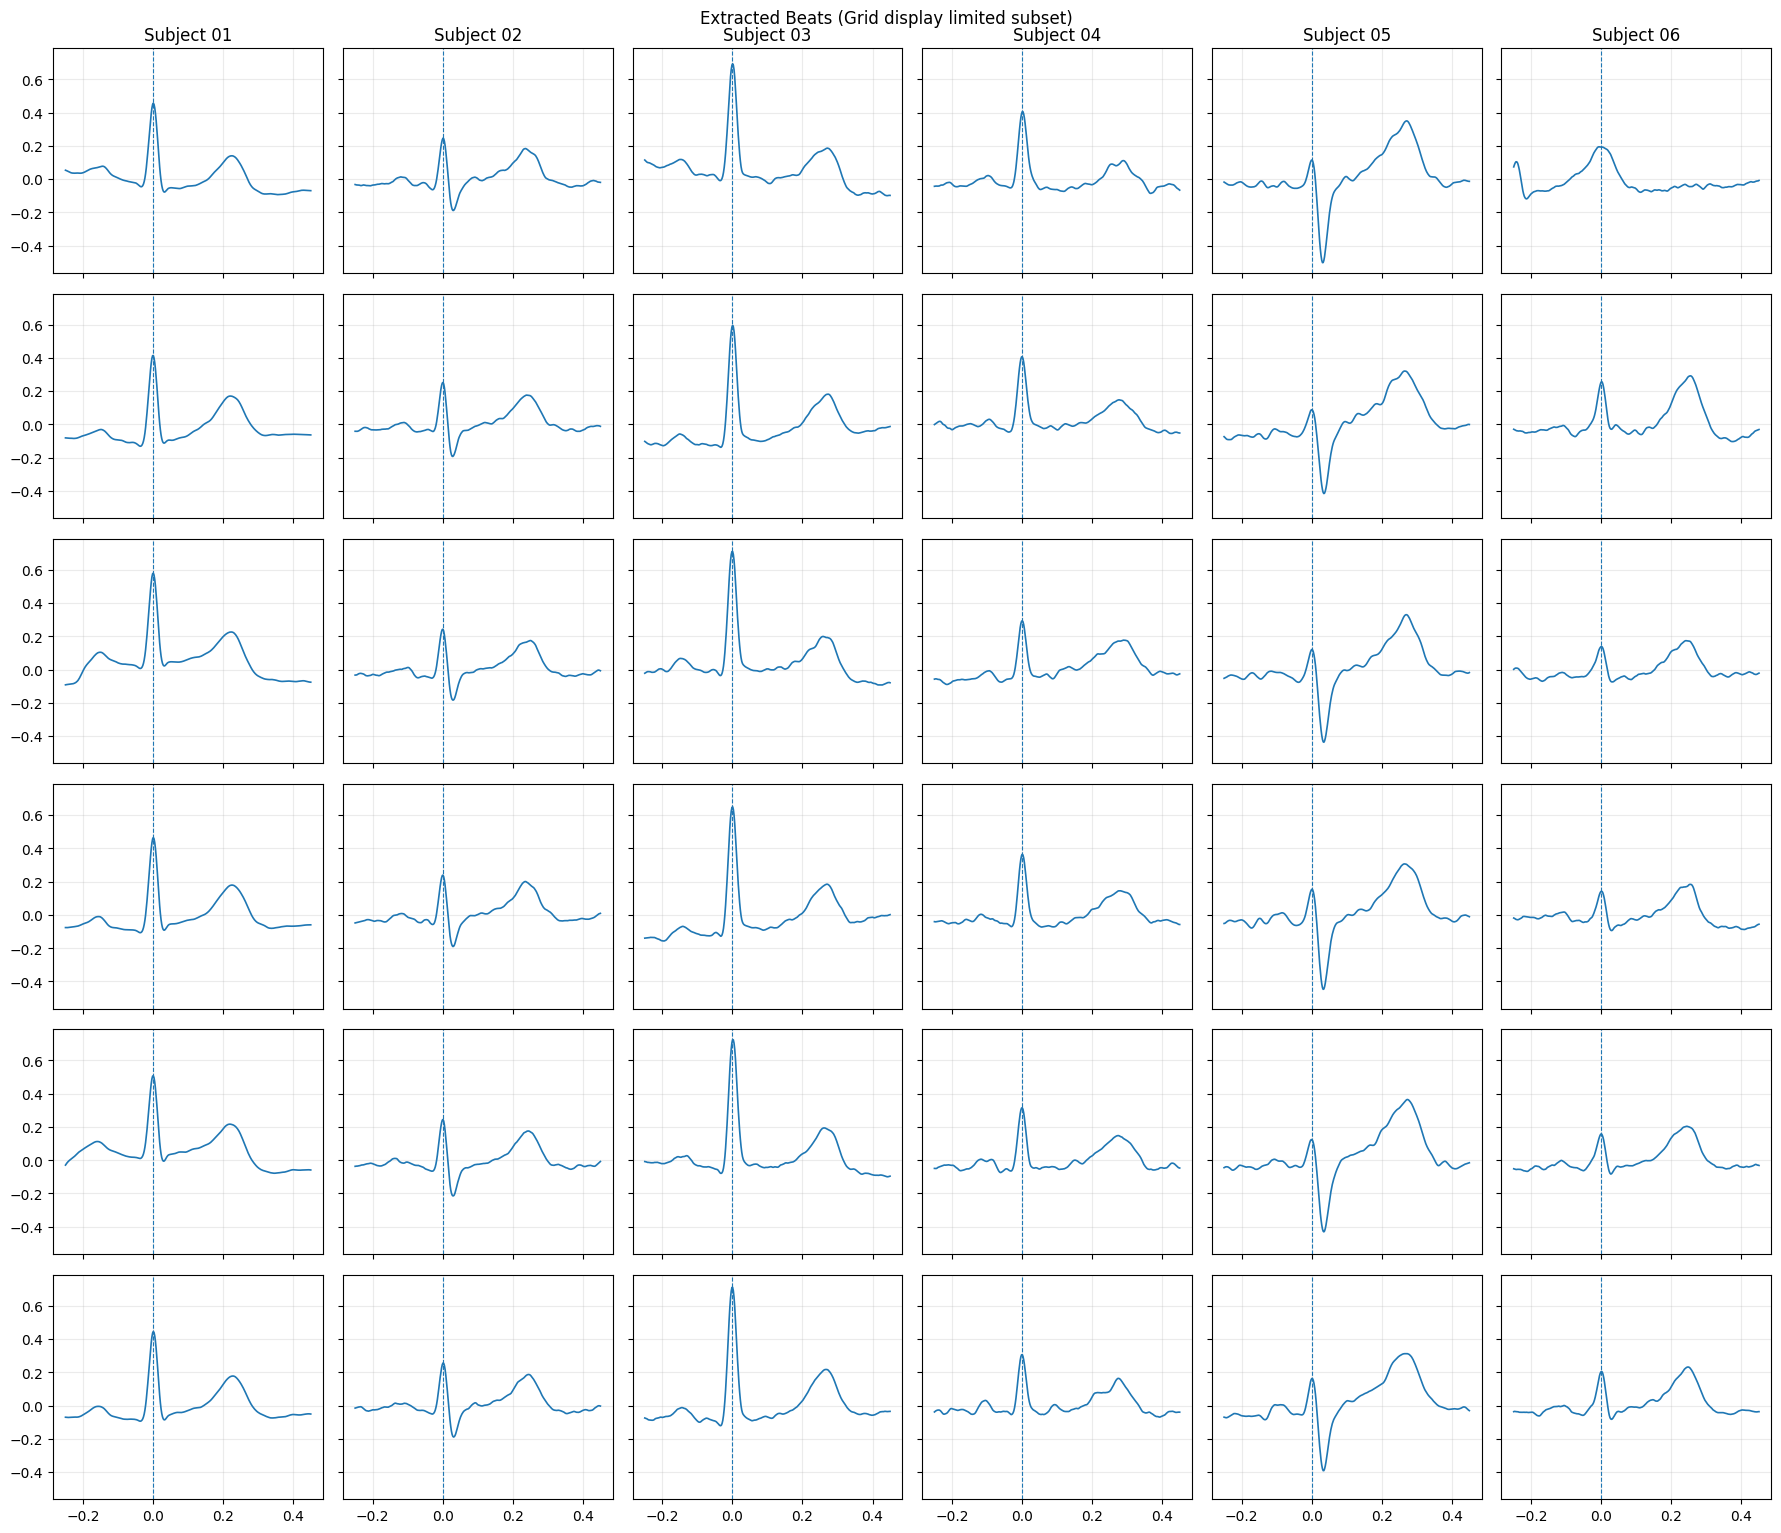

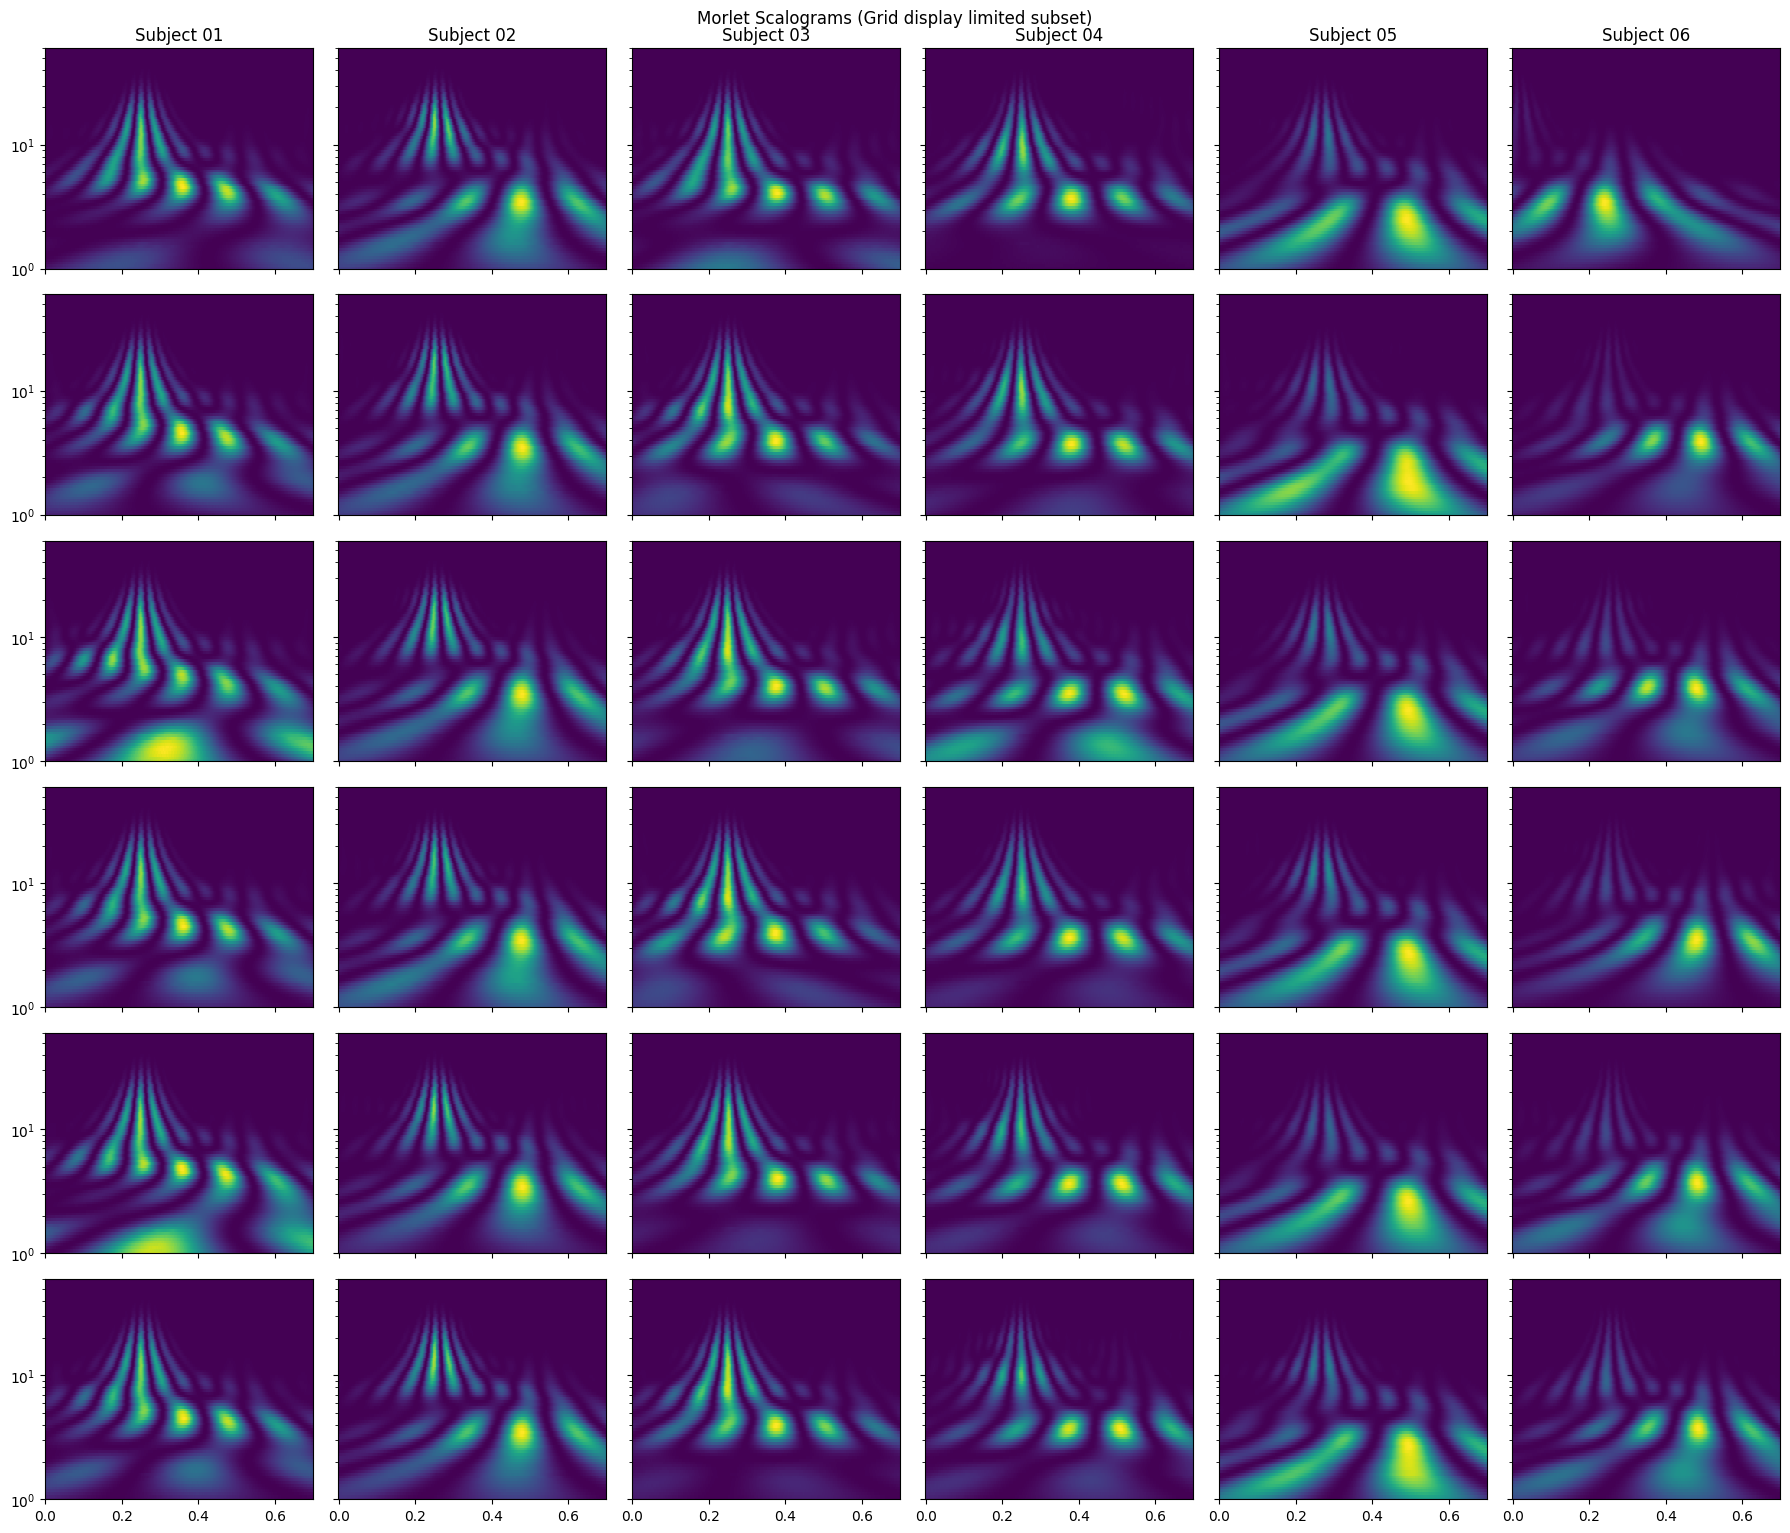

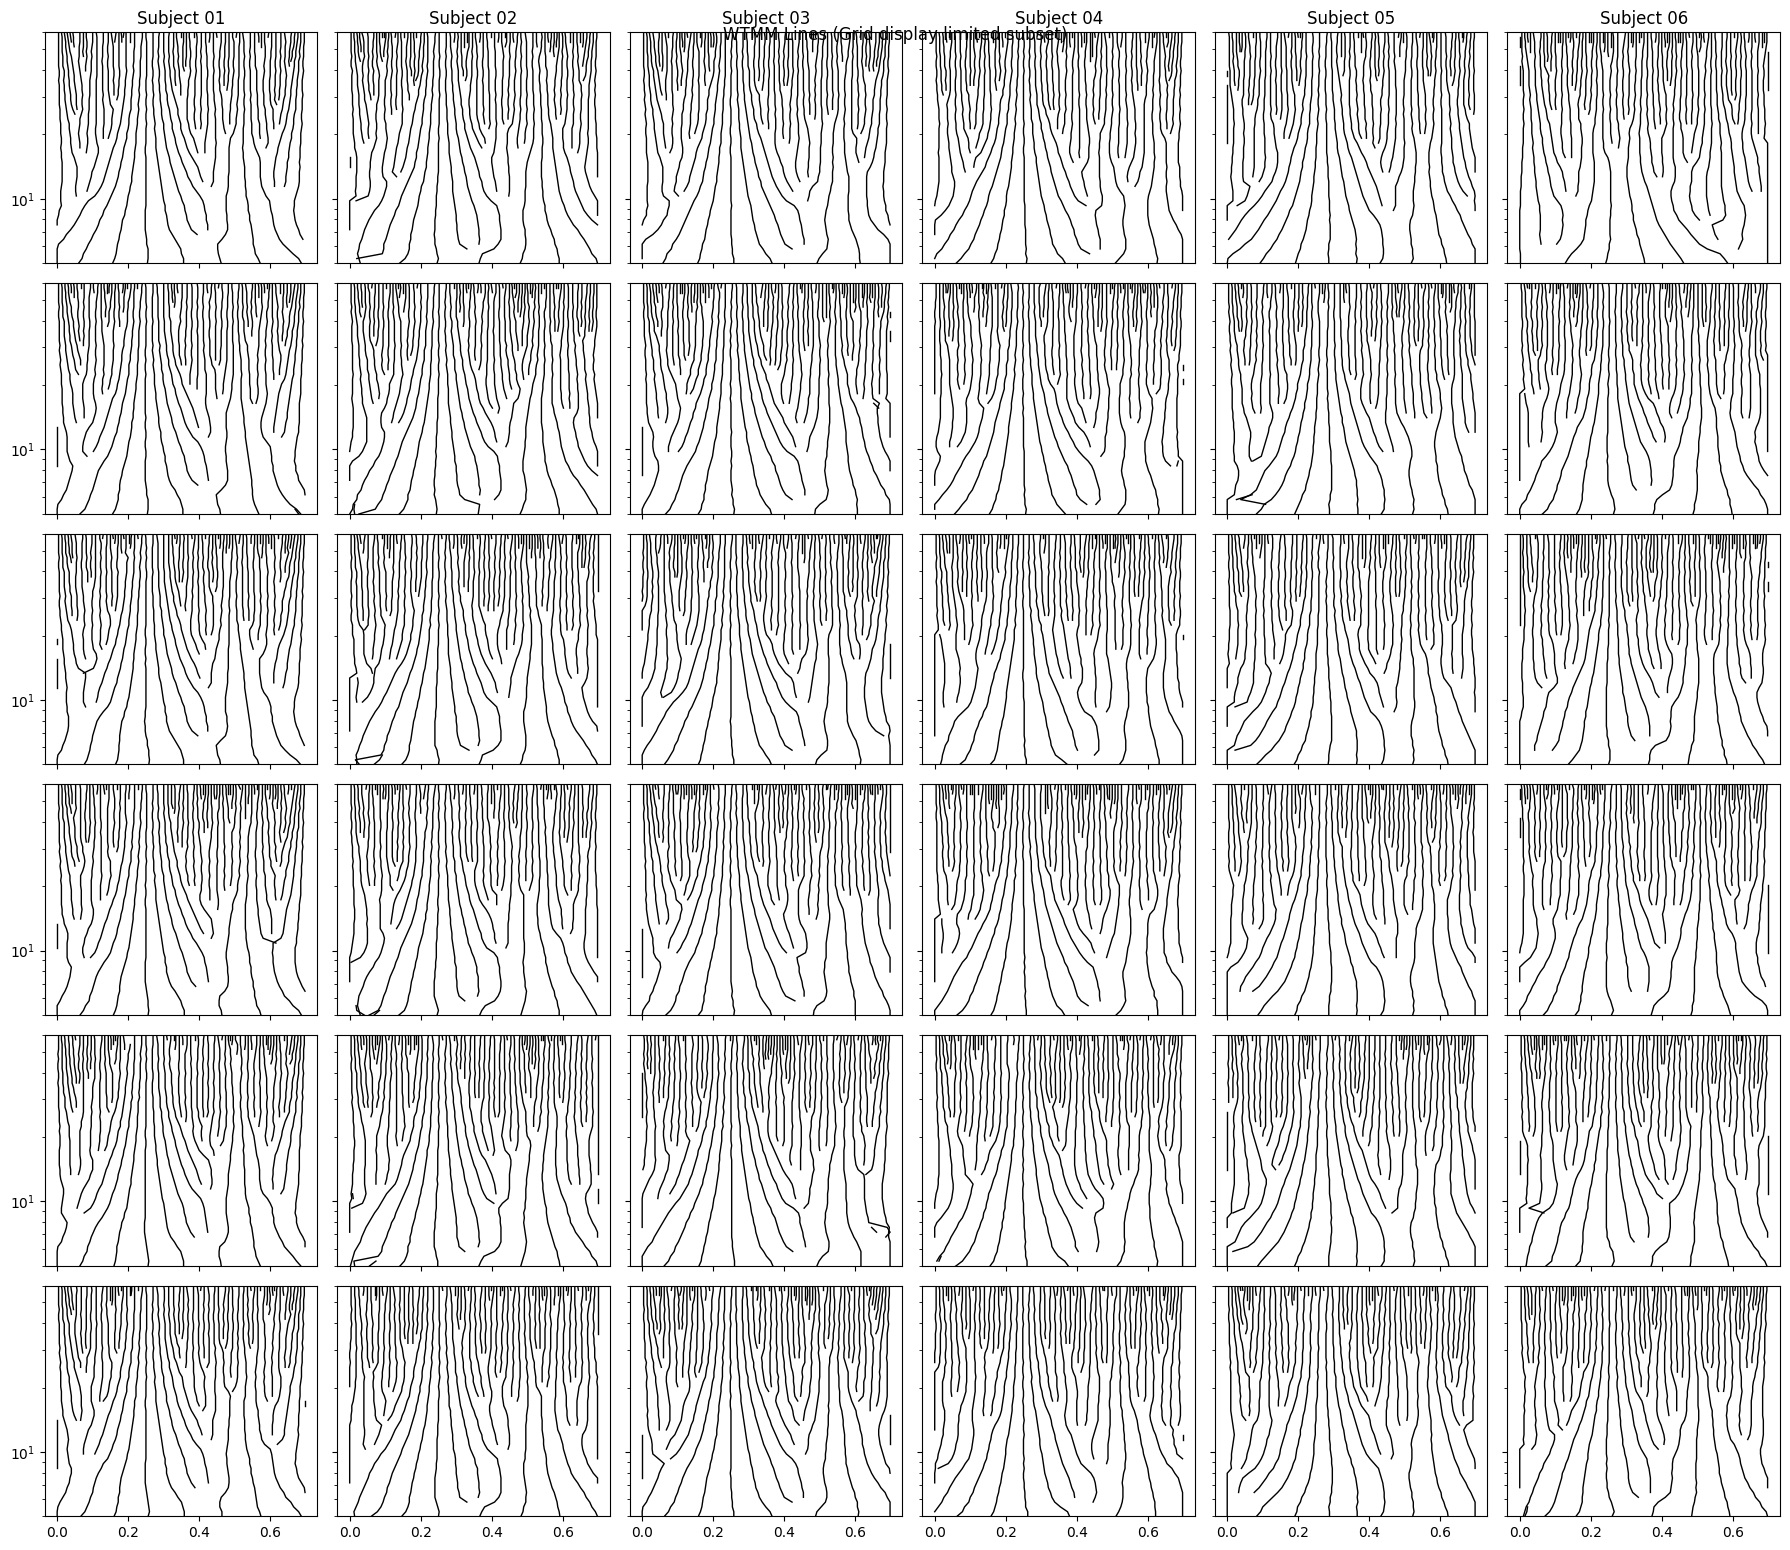


Finished processing. Individual WTMM images saved in: ./ecg_wtmm_images
Grid displays limited to first 6 subjects and first 6 beats per subject.


In [5]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
import pywt
import wfdb

try:
    import neurokit2 as nk
    HAS_NK = True
except Exception:
    HAS_NK = False

# -----------------------
# User / run settings
# -----------------------
OUT_DIR = './ecg_morlet_wtmm'
IMAGE_DIR = './ecg_wtmm_images'
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(IMAGE_DIR, exist_ok=True)

# How many subjects to process (reads Person_01 .. Person_N)
NUM_SUBJECTS = 10          # keep processing up to 10 subjects (change as needed)

# Plotting grid: how many subjects & beats to display in the grid figures
GRID_SUBJECTS = 6          # number of columns shown in grid display (must be <= NUM_SUBJECTS)
GRID_BEATS = 6             # number of beats per subject shown in grid display

# Beat extraction window (ms)
PRE_MS = 250
POST_MS = 450

# Wavelet / WTMM parameters
WAVELET_NAME = 'morl'
FREQ_MIN = 1.0
FREQ_MAX = 60.0
N_FREQS = 80
CUT_FREQ = 5.0  # min displayed frequency in WTMM grid

# Other
FS_DEFAULT = 500  # fallback sampling frequency if missing in record

# -----------------------
# Helper functions
# -----------------------
def bandpass_filter(sig, fs, low=0.5, high=40.0, order=4):
    from scipy.signal import butter, filtfilt
    nyq = 0.5 * fs
    b, a = butter(order, [low/nyq, high/nyq], btype='band')
    return filtfilt(b, a, sig)

def detect_rpeaks(sig, fs):
    """Return r-peak indices (sample indices), method string, and cleaned ECG used for detection."""
    if HAS_NK:
        try:
            signals, info = nk.ecg_process(sig, sampling_rate=fs)
            cleaned = signals['ECG_Clean'].values
            r_idx = info['ECG_R_Peaks']
            return np.array(r_idx), 'neurokit2', cleaned
        except Exception as e:
            print("neurokit2 detection failed, falling back to scipy approach:", e)

    # Fallback: simple bandpass + find_peaks
    cleaned = bandpass_filter(sig, fs)
    min_dist = int(0.35 * fs)  # at least 0.35s between R peaks
    # prominence tuned reasonably for many ECGs; adjust if too many/few peaks
    peaks, _ = find_peaks(cleaned, distance=min_dist, prominence=0.35)
    return np.array(peaks), 'scipy_fallback', cleaned

def extract_beats(cleaned, r_idx, fs, method, pre_ms=PRE_MS, post_ms=POST_MS):
    """Return beats array (n_beats x n_samples) and time vector for one beat.
       If no beats found, return empty array with consistent time axis length."""
    pre_s = pre_ms / 1000.0
    post_s = post_ms / 1000.0

    if method == 'neurokit2' and HAS_NK:
        # epochs_create expects pandas-like index; using neurokit epochs if available
        try:
            epochs = nk.epochs_create(cleaned, events=r_idx, sampling_rate=fs,
                                      epochs_start=-pre_s, epochs_end=post_s)
            # epochs keys are strings; sort by integer cast
            sorted_keys = sorted(epochs.keys(), key=lambda k: int(k))
            beats = [epochs[key]['Signal'].values for key in sorted_keys]
            t_beat = epochs[sorted_keys[0]].index.values
            # convert t_beat (pandas DatetimeIndex-like) to seconds relative
            # epochs_create returns a RangeIndex with times in seconds if provided a vector
            # to be safe, produce a simple time vector:
            time_vec = np.linspace(-pre_s, post_s, beats[0].size)
            return np.array(beats), time_vec
        except Exception as e:
            print("neurokit2 epoch extraction failed, falling back to manual slicing:", e)

    # Manual slicing fallback
    pre = int(round(pre_s * fs))
    post = int(round(post_s * fs))
    beats = []
    for idx in r_idx:
        s = int(idx) - pre
        e = int(idx) + post
        if s < 0 or e > len(cleaned):
            # skip beats that don't fit in the signal window
            continue
        beats.append(cleaned[s:e])
    if len(beats) == 0:
        # Return empty consistent shape (0, pre+post) and a time vector
        n_samples = pre + post
        return np.empty((0, n_samples)), np.linspace(-pre_s, post_s, n_samples)
    beats = np.vstack(beats)
    time_beat = np.linspace(-pre_s, post_s, beats.shape[1])
    return beats, time_beat

def compute_wtmm_lines(power, scales, min_len=2):
    """Compute WTMM lines (list of lines). Each line is list of (scale_index, time_index)."""
    # power shape: (n_scales, n_times)
    n_scales, n_times = power.shape
    maxima_mask = np.zeros_like(power, dtype=bool)

    # local maxima along time for each scale
    # handle edges: treat them as maxima if greater than neighbor
    for s in range(n_scales):
        row = power[s]
        # interior
        if n_times >= 3:
            maxima_mask[s, 1:-1] = (row[1:-1] > row[0:-2]) & (row[1:-1] > row[2:])
        # edges
        if n_times >= 2:
            maxima_mask[s, 0] = row[0] > row[1]
            maxima_mask[s, -1] = row[-1] > row[-2]
        else:
            maxima_mask[s, 0] = True

    maxima_idx = [np.where(maxima_mask[s])[0].tolist() for s in range(n_scales)]

    used = [set() for _ in range(n_scales)]
    lines = []
    for s0 in range(n_scales):
        for t0 in maxima_idx[s0]:
            if t0 in used[s0]:
                continue
            line = [(s0, t0)]
            used[s0].add(t0)
            prev_t = t0
            for s in range(s0 + 1, n_scales):
                # tolerance in time index depends on scale: use approx half-scale in samples
                tol = max(1, int(round(scales[s] / 2.0)))
                cands = [tt for tt in maxima_idx[s] if tt not in used[s] and abs(int(tt) - int(prev_t)) <= tol]
                if not cands:
                    break
                # pick candidate closest in time
                nxt = min(cands, key=lambda x: abs(x - prev_t))
                line.append((s, int(nxt)))
                used[s].add(int(nxt))
                prev_t = int(nxt)
            if len(line) >= min_len:
                lines.append(line)
    return lines

# -----------------------
# Ensure database present
# -----------------------
if not os.path.exists('./ecgiddb'):
    print("Downloading ECG-ID database (this can take some time)...")
    wfdb.dl_database('ecgiddb', './ecgiddb')
else:
    print("ECG-ID database already exists, skipping download.")

# -----------------------
# Data containers
# -----------------------
all_subjects_signals = {}
all_subjects_beats = {}     # stores all beats per subject (no slicing)
all_subjects_t_beat = {}
all_subjects_fs = {}

# -----------------------
# Read & process each subject
# -----------------------
for subj_idx in range(NUM_SUBJECTS):
    subj_num = subj_idx + 1
    rec_name = f'./ecgiddb/Person_{subj_num:02d}/rec_1'
    print(f"\n--- Processing Subject {subj_num:02d} ---")
    try:
        rec = wfdb.rdrecord(rec_name)
    except Exception as e:
        print(f"Could not read {rec_name}: {e}. Skipping subject.")
        continue

    # pick first channel if multiple
    try:
        sig = rec.p_signal[:, 0]
    except Exception:
        sig = np.asarray(rec.p_signal).flatten()
    fs = getattr(rec, 'fs', FS_DEFAULT) or FS_DEFAULT

    all_subjects_signals[subj_idx] = sig
    all_subjects_fs[subj_idx] = fs

    # Detect r-peaks and extract beats (ALL beats available)
    r_idx, method, cleaned = detect_rpeaks(sig, fs)
    beats, t_beat = extract_beats(cleaned, r_idx, fs, method)
    print(f"  Detected {len(r_idx)} R-peaks, extracted {beats.shape[0]} beats for subject {subj_num:02d} (fs={fs})")

    all_subjects_beats[subj_idx] = beats
    all_subjects_t_beat[subj_idx] = t_beat

# central frequency for morlet
cf = pywt.central_frequency(WAVELET_NAME)

# -----------------------
# Grid: Original signals (show only GRID_SUBJECTS)
# -----------------------
n_show_subjects = min(GRID_SUBJECTS, len(all_subjects_signals))
ncols = min(3, n_show_subjects)
nrows = int(np.ceil(n_show_subjects / ncols))
fig_orig, axes_orig = plt.subplots(nrows, ncols, figsize=(18, nrows * 4), squeeze=False)
axes_orig = axes_orig.flatten()

for i_sub in range(n_show_subjects):
    sig = all_subjects_signals[i_sub]
    fs = all_subjects_fs[i_sub]
    t_sig = np.arange(len(sig)) / fs
    ax = axes_orig[i_sub]
    ax.plot(t_sig, sig, lw=0.8)
    ax.set_title(f'Original Signal - Subject {i_sub+1:02d}')
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Amplitude')
    ax.grid(alpha=0.25)
# turn off remaining axes
for ax in axes_orig[n_show_subjects:]:
    ax.axis('off')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'original_signals_grid.png'), dpi=220)
plt.show()

# -----------------------
# Grid: Extracted beats (rows: GRID_BEATS, cols: GRID_SUBJECTS)
# Only display the first GRID_BEATS of each subject (if available).
# -----------------------
fig_beats, axes_beats = plt.subplots(GRID_BEATS, n_show_subjects,
                                     figsize=(3*n_show_subjects, 2.6*GRID_BEATS),
                                     squeeze=False, sharex=True, sharey=True)

for col_sub in range(n_show_subjects):
    beats = all_subjects_beats.get(col_sub, np.empty((0,)))
    t_beat = all_subjects_t_beat.get(col_sub, np.linspace(-PRE_MS/1000., POST_MS/1000., int((PRE_MS+POST_MS)/1000.*all_subjects_fs.get(col_sub, FS_DEFAULT))))
    n_beats = beats.shape[0]
    for row_beat in range(GRID_BEATS):
        ax = axes_beats[row_beat, col_sub]
        if row_beat < n_beats:
            ax.plot(t_beat, beats[row_beat], lw=1.2)
            ax.axvline(0, linestyle='--', lw=0.8)
            ax.grid(alpha=0.25)
            if row_beat == 0:
                ax.set_title(f'Subject {col_sub+1:02d}')
        else:
            ax.axis('off')

fig_beats.suptitle('Extracted Beats (Grid display limited subset)')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'extracted_beats_grid.png'), dpi=220)
plt.show()

# -----------------------
# Morlet scalograms grid for the limited subset only
# -----------------------
fig_morlet, axes_morlet = plt.subplots(GRID_BEATS, n_show_subjects,
                                       figsize=(3*n_show_subjects, 2.6*GRID_BEATS),
                                       squeeze=False, sharex=True, sharey=True)

for col_sub in range(n_show_subjects):
    beats = all_subjects_beats.get(col_sub, np.empty((0,)))
    fs = all_subjects_fs.get(col_sub, FS_DEFAULT)
    freqs = np.logspace(np.log10(FREQ_MIN), np.log10(FREQ_MAX), N_FREQS)
    scales = cf * fs / freqs
    n_beats = beats.shape[0]
    for row_beat in range(GRID_BEATS):
        ax = axes_morlet[row_beat, col_sub]
        if row_beat < n_beats:
            coeffs, freqs_out = pywt.cwt(beats[row_beat], scales, WAVELET_NAME, sampling_period=1.0/fs)
            power = np.abs(coeffs) ** 2
            T, F = np.meshgrid(np.arange(beats[row_beat].size)/fs, freqs_out)
            pcm = ax.pcolormesh(T, F, power, shading='auto')
            ax.set_yscale('log')
            ax.set_ylim([FREQ_MIN, FREQ_MAX])
            if row_beat == 0:
                ax.set_title(f'Subject {col_sub+1:02d}')
        else:
            ax.axis('off')

fig_morlet.suptitle('Morlet Scalograms (Grid display limited subset)')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'morlet_scalograms_grid.png'), dpi=220)
plt.show()

# -----------------------
# WTMM: process & SAVE images for ALL beats for each subject,
# and create a grid view for the limited subset only.
# -----------------------
fig_wtmm, axes_wtmm = plt.subplots(GRID_BEATS, n_show_subjects,
                                   figsize=(3*n_show_subjects, 2.6*GRID_BEATS),
                                   squeeze=False, sharex=True, sharey=True)

for subj_idx in range(NUM_SUBJECTS):
    subj_num = subj_idx + 1
    beats = all_subjects_beats.get(subj_idx, np.empty((0,)))
    if beats.size == 0:
        print(f"Subject {subj_num:02d}: no beats extracted, skipping WTMM.")
        continue
    fs = all_subjects_fs.get(subj_idx, FS_DEFAULT)
    freqs = np.logspace(np.log10(FREQ_MIN), np.log10(FREQ_MAX), N_FREQS)
    scales = cf * fs / freqs

    subj_dir = os.path.join(IMAGE_DIR, f'subject_{subj_num:02d}')
    os.makedirs(subj_dir, exist_ok=True)

    # Process every beat and save individual WTMM-line images (for ML / dataset)
    for b_idx in range(beats.shape[0]):
        beat = beats[b_idx]
        coeffs, freqs_out = pywt.cwt(beat, scales, WAVELET_NAME, sampling_period=1.0/fs)
        power = np.abs(coeffs) ** 2
        lines = compute_wtmm_lines(power, scales, min_len=2)

        # Save each individual image (no axes, minimal margins) - these are for ML
        fig_ind, ax_ind = plt.subplots(figsize=(3, 3))
        for line in lines:
            xs = [t_idx / fs for s_idx, t_idx in line]
            ys = [freqs_out[s_idx] for s_idx, t_idx in line]
            ax_ind.plot(xs, ys, '-', lw=1.0)
        ax_ind.set_yscale('log')
        ax_ind.set_ylim([CUT_FREQ, max(freqs_out)])
        ax_ind.axis('off')
        fname = os.path.join(subj_dir, f'wtmm_beat_{b_idx+1:03d}.png')
        plt.savefig(fname, bbox_inches='tight', pad_inches=0)
        plt.close(fig_ind)

    # If subject is inside the plotting subset, add to the WTMM grid the first GRID_BEATS
    if subj_idx < n_show_subjects:
        n_beats_here = beats.shape[0]
        for row_beat in range(GRID_BEATS):
            ax = axes_wtmm[row_beat, subj_idx]
            if row_beat < n_beats_here:
                beat = beats[row_beat]
                coeffs, freqs_out = pywt.cwt(beat, scales, WAVELET_NAME, sampling_period=1.0/fs)
                power = np.abs(coeffs) ** 2
                lines = compute_wtmm_lines(power, scales, min_len=2)
                for line in lines:
                    xs = [t_idx / fs for s_idx, t_idx in line]
                    ys = [freqs_out[s_idx] for s_idx, t_idx in line]
                    ax.plot(xs, ys, '-', color='black', lw=1.0)
                ax.set_yscale('log')
                ax.set_ylim([CUT_FREQ, max(freqs_out)])
                if row_beat == 0:
                    ax.set_title(f'Subject {subj_idx+1:02d}')
            else:
                ax.axis('off')

plt.tight_layout()
fig_wtmm.suptitle('WTMM Lines (Grid display limited subset)')
plt.savefig(os.path.join(OUT_DIR, 'wtmm_lines_grid.png'), dpi=220)
plt.show()

print('\nFinished processing. Individual WTMM images saved in:', IMAGE_DIR)
print('Grid displays limited to first', n_show_subjects, 'subjects and first', GRID_BEATS, 'beats per subject.')
